# Pulsar timing with PINT (Section 5)

The TOAs come from `pipeline/02_make_toas.sh` (`data/toas.tim`, one per observation, and
`data/toas_within_2021A.tim`, three within NICER 2021A). This notebook builds the initial
frequency step by step and fits the timing model.

| cell | paper item | file |
|---|---|---|
| Within-observation residual slopes | Figure 7, Section 5.3 | `pint_initial_center_prefit.pdf`, `pint_initial_center_postfit.pdf` |
| Residual slopes for the five candidate aliases | Figure 8 (bottom) | `pint_resid_slopes.pdf` |
| Pre-fit residuals of the three initial models | Figure 6 | `prefit_residuals.pdf` |
| Successive frequency estimates | Figure 9 | `initial_frequency_plot.pdf` |
| PINT fit for $f$ and $\dot f$ | Figure 10, Section 5.4 | `pint_prefit_resids.pdf`, `pint_postfit_resids.pdf` |
| Joint confidence ellipse | Figure 11 | `pint_error_ellipse.pdf` |
| Numbers quoted in the paper | Sections 5.3 and 5.4 | printed at the end |

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import astropy.units as u

import pint.logging
import pint.models
import pint.toa
import pint.residuals
from pint.models import model_builder, PhaseOffset
from pint.fitter import DownhillWLSFitter, WLSFitter

import config
import plotting

pint.logging.setup(level='WARNING')
savedir = config.FIGURE_DIR

## Section 5.3: the initial frequency

The maximum tolerable frequency error is set by the longest gap between TOAs (678 days):
$\Delta f_{\max} = 0.5 / T_{\rm gap} \approx 8.5 \times 10^{-9}$ Hz.

In [2]:
delta_f_max = 0.5 / (678 * 86400)
print(f'maximum tolerable frequency error: {delta_f_max:.2e} Hz')

maximum tolerable frequency error: 8.54e-09 Hz


### Residual slopes of the three TOAs within NICER 2021A for the candidate alias frequencies (Figure 7: central alias; Figure 8 bottom: all five)

center     par f = 0.03377273 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


leftpeak   par f = 0.03377261 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


leftpeak2  par f = 0.03377250 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


rightpeak  par f = 0.03377285 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


rightpeak2 par f = 0.03377297 Hz -> fit f = 0.03377271489 +/- 3.75e-08 Hz


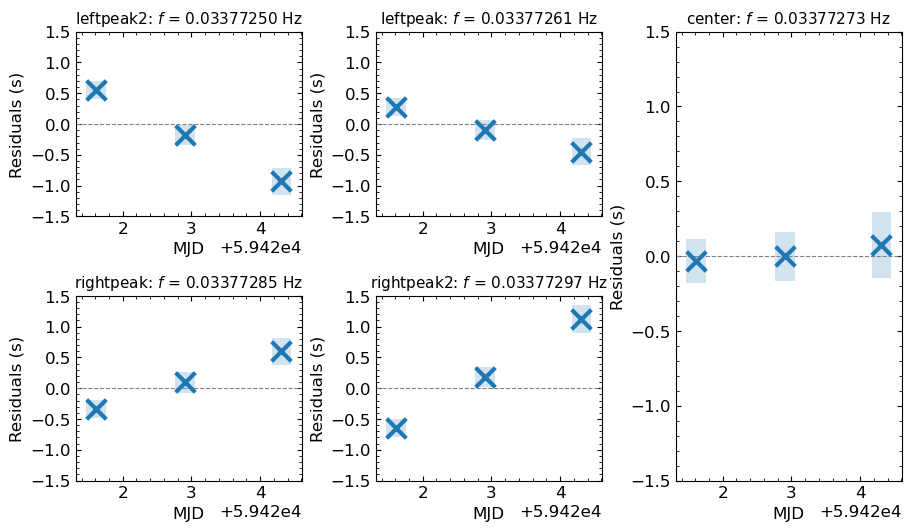

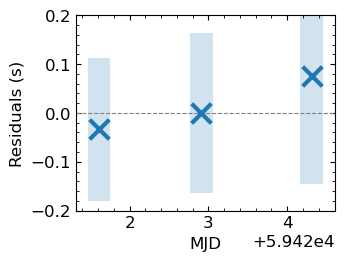

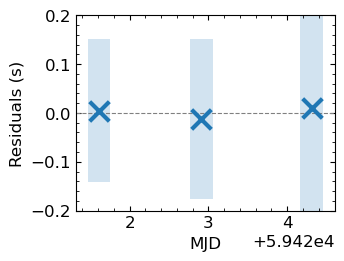

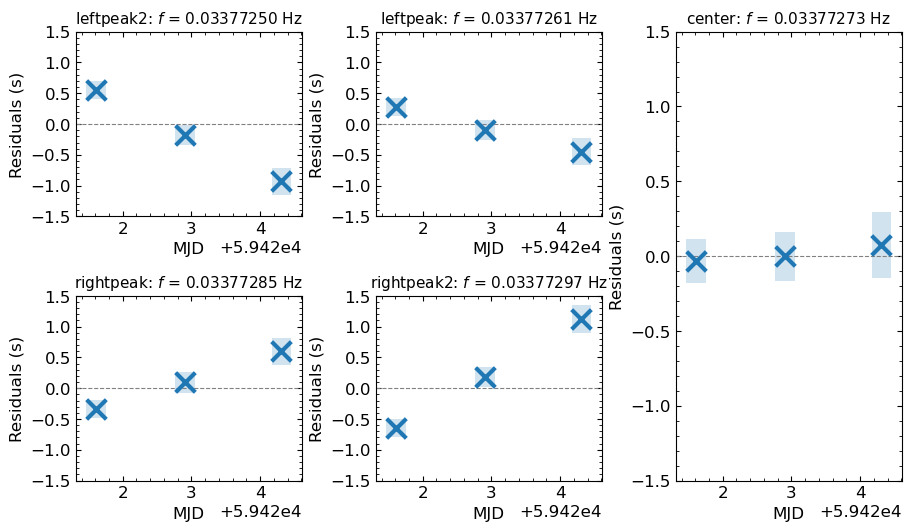

In [3]:
par_files = {'center': 'test_timing_model', 'leftpeak': 'CTCV_leftpeak', 'leftpeak2': 'CTCV_leftpeak2',
             'rightpeak': 'CTCV_rightpeak', 'rightpeak2': 'CTCV_rightpeak2'}
toas_within = pint.toa.get_TOAs(config.TOAS_WITHIN)
mjds_w = toas_within.get_mjds().value
errs_w = toas_within.get_errors().to(u.s).value
bar_width = 0.107 * (np.max(mjds_w) - np.min(mjds_w))

panels = {}
for label, name in par_files.items():
    m = pint.models.get_model(f'{config.DATA_DIR}/{name}.par')
    m.F1.frozen = True
    pre = pint.residuals.Residuals(toas_within, m).time_resids.to(u.s).value
    fitter_w = WLSFitter(toas_within, m)
    fitter_w.fit_toas()
    post = fitter_w.resids.time_resids.to(u.s).value
    panels[label] = (mjds_w, pre, errs_w, float(m.F0.value))
    print(f"{label:10s} par f = {m.F0.value:.8f} Hz -> fit f = {fitter_w.model.F0.value:.11f} +/- {fitter_w.model.F0.uncertainty.value:.2e} Hz")
    if label == 'center':
        f_slope, f_slope_err = fitter_w.model.F0.value, fitter_w.model.F0.uncertainty.value
        plotting.plot_within_residuals(mjds_w, pre, errs_w, bar_width, path=f'{savedir}/pint_initial_center_prefit.pdf')
        plotting.plot_within_residuals(mjds_w, post, errs_w, bar_width, path=f'{savedir}/pint_initial_center_postfit.pdf')

plotting.plot_resid_slopes_montage(panels, bar_width, path=f'{savedir}/pint_resid_slopes.pdf')

### Figure 6: pre-fit residuals of the five TOAs for the three successive initial models

timing_model_z2            f = 0.0337727000 +/- 1.8e-07 Hz, pre-fit wrms 3.415 s
timing_model_resid_slope   f = 0.0337727140 +/- 3.8e-08 Hz, pre-fit wrms 3.984 s
timing_model_centerpeak    f = 0.0337727321 +/- 8.8e-09 Hz, pre-fit wrms 0.571 s


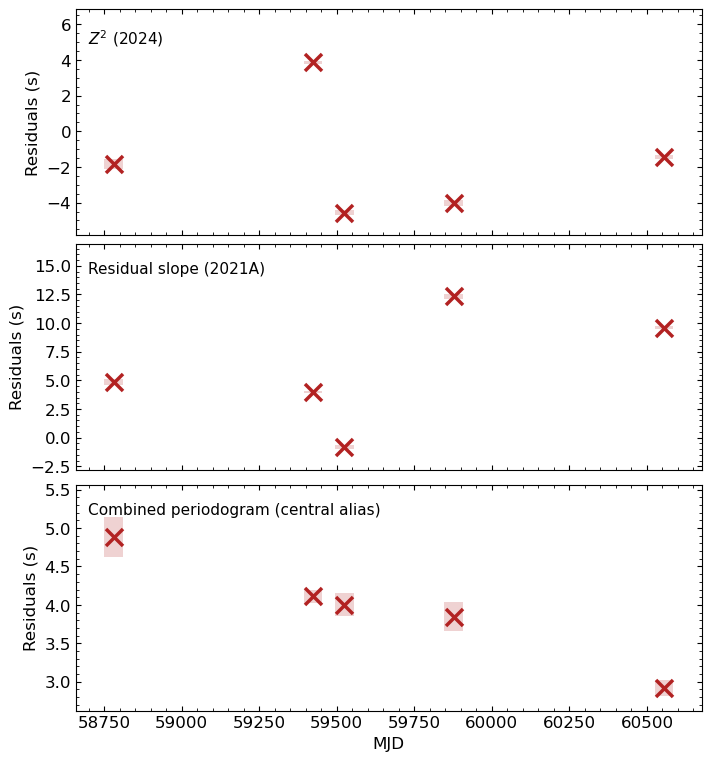

In [4]:
stages = [('timing_model_z2', r'$Z^2$ (2024)'), ('timing_model_resid_slope', 'Residual slope (2021A)'),
          ('timing_model_centerpeak', 'Combined periodogram (central alias)')]
prefit_panels = []
initial = []   # (f, sigma_f) of each stage, for Figure 9
for name, label in stages:
    m, toas_stage = model_builder.get_model_and_toas(f'{config.DATA_DIR}/{name}.par', config.TOAS)
    res = pint.residuals.Residuals(toas_stage, m, subtract_mean=False)
    prefit_panels.append((label, res.toas.get_mjds().value, res.time_resids.to(u.s).value, res.toas.get_errors().to(u.s).value))
    initial.append((float(m.F0.value), float(m.F0.uncertainty_value)))
    print(f'{name:26s} f = {m.F0.value:.10f} +/- {m.F0.uncertainty_value:.1e} Hz, pre-fit wrms {res.rms_weighted().to(u.s).value:.3f} s')

plotting.plot_prefit_montage(prefit_panels, path=f'{savedir}/prefit_residuals.pdf')

## Section 5.4: fit for $f$ and $\dot f$ (with a phase offset) from the central-alias initial model

5 TOAs, MJD 58780.58 d to 60554.68 d
Fitted model using downhill_wls method with 3 free parameters to 5 TOAs
Prefit residuals Wrms = 570806.050948584 us, Postfit residuals Wrms = 63680.074296121646 us
Chisq = 1.254 for 1 d.o.f. for reduced Chisq of 1.254

PAR                   Prefit                  Postfit            Units
============== ==================== ============================ =====
EPHEM                         DE440 DE440                        None
CLOCK                               TT(BIPM2023)                 None
UNITS                           TDB TDB                          None
START                                                    58780.6 d 
FINISH                                                   60554.7 d 
DILATEFREQ                        N                              None
DMDATA                            N                              None
NTOA                              0                              None 
CHI2                                         

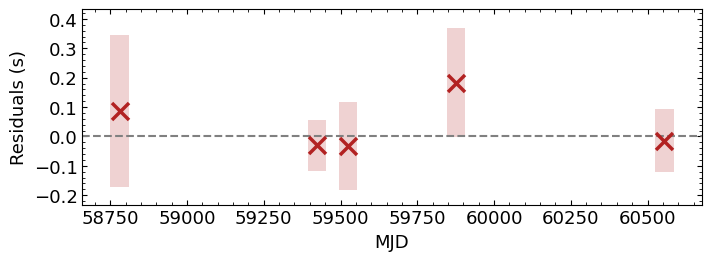

In [5]:
model, toas = model_builder.get_model_and_toas(f'{config.DATA_DIR}/timing_model_centerpeak.par', config.TOAS)
print(f'{len(toas)} TOAs, MJD {toas.get_mjds().min():.2f} to {toas.get_mjds().max():.2f}')

# Figure 10 (left): pre-fit residuals
res = pint.residuals.Residuals(toas, model, subtract_mean=False)
mjds = res.toas.get_mjds().value
pre = res.time_resids.to(u.s).value
errs = res.toas.get_errors().to(u.s).value
plotting.plot_toa_residuals(mjds, pre, errs, ylim=(np.min(pre) - 0.3, np.max(pre) * 1.1), path=f'{savedir}/pint_prefit_resids.pdf')

# Fit F0, F1 and a phase offset
model.F0.frozen = False
model.F1.frozen = False
model.add_component(PhaseOffset())
model.PHOFF.frozen = False
fitter = DownhillWLSFitter(toas, model)
fitter.fit_toas()
print(fitter.print_summary())

# Figure 10 (right): post-fit residuals
post = fitter.resids.time_resids.to(u.s).value
plotting.plot_toa_residuals(mjds, post, errs, zero_line=True, ylim=(np.min(post) - 0.2, np.max(post) + 0.25), path=f'{savedir}/pint_postfit_resids.pdf')

### Figure 11: joint confidence ellipse of $f$ and $\dot f$

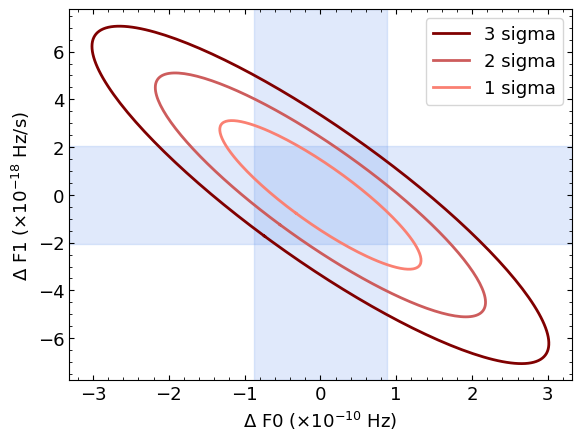

In [6]:
param_names = [label[0] for label in fitter.parameter_correlation_matrix.labels[0]]
i0, i1 = param_names.index('F0'), param_names.index('F1')
full_corr = fitter.parameter_correlation_matrix.matrix
corr = np.array([[full_corr[i0, i0], full_corr[i0, i1]], [full_corr[i1, i0], full_corr[i1, i1]]])
sigmas = np.array([fitter.get_fitparams_uncertainty()[p] for p in ['F0', 'F1']])

plotting.plot_error_ellipse(corr, sigmas, path=f'{savedir}/pint_error_ellipse.pdf')

### The $f$-only model: $\dot f$ is consistent with zero, so the reduced model gives the adopted $f$

In [7]:
model.F1.frozen = True
fitter2 = DownhillWLSFitter(toas, model)
fitter2.fit_toas()
print(fitter2.print_summary())

Fitted model using downhill_wls method with 2 free parameters to 5 TOAs
Prefit residuals Wrms = 570806.050948584 us, Postfit residuals Wrms = 64065.63897939222 us
Chisq = 1.269 for 2 d.o.f. for reduced Chisq of 0.635

PAR                   Prefit                  Postfit            Units
============== ==================== ============================ =====
EPHEM                         DE440 DE440                        None
CLOCK                               TT(BIPM2023)                 None
UNITS                           TDB TDB                          None
START                                                    58780.6 d 
FINISH                                                   60554.7 d 
DILATEFREQ                        N                              None
DMDATA                            N                              None
NTOA                              0                              None 
CHI2                                                     1.26902  
CHI2R           

### Figure 9: the successive initial-frequency estimates compared with the final fit

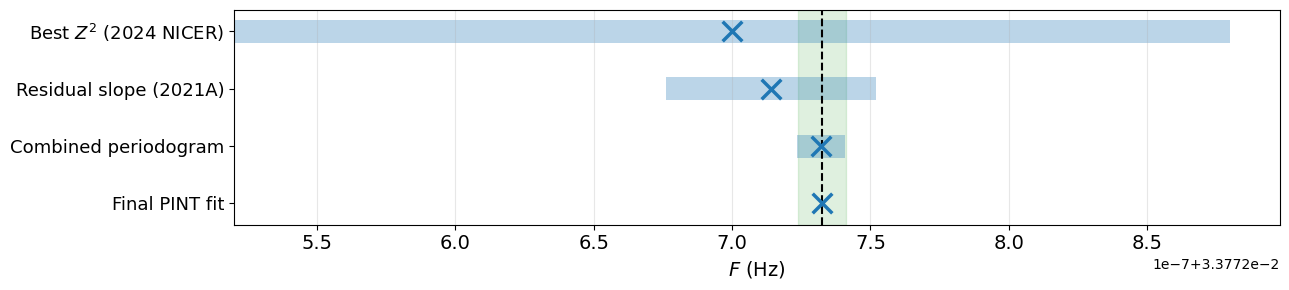

In [8]:
labels = [r'Best $Z^2$ (2024 NICER)', r'Residual slope (2021A)', r'Combined periodogram', r'Final PINT fit']
freqs = np.array([f for f, _ in initial] + [float(fitter2.model.F0.value)])
uncerts = np.array([df for _, df in initial] + [float(fitter2.model.F0.uncertainty_value)])
plotting.plot_initial_frequency(labels, freqs, uncerts, delta_f_max, path=f'{savedir}/initial_frequency_plot.pdf')

## Numbers quoted in the paper

In [9]:
F0, F0_err = fitter.model.F0.quantity.value, fitter.model.F0.uncertainty.value
F1, F1_err = fitter.model.F1.quantity.value, fitter.model.F1.uncertainty.value
f_only, f_only_err = fitter2.model.F0.quantity.value, fitter2.model.F0.uncertainty.value
print(f'Residual-slope frequency (2021A): f = {f_slope * 1e3:.6f} +/- {f_slope_err * 1e3:.6f} mHz')
print(f'Two-parameter fit: f = {F0:.11f} +/- {F0_err:.1e} Hz, f-dot = {F1:.1e} +/- {F1_err:.1e} Hz/s, '
      f'corr = {corr[0, 1]:.2f}, chi2 = {fitter.resids.chi2:.3f} for {fitter.resids.dof} dof, post-fit wrms = {fitter.resids.rms_weighted().to(u.s).value:.3f} s')
print(f'f-only fit: f = {f_only:.11f} +/- {f_only_err:.1e} Hz')
print(f'P = {1 / f_only:.8f} +/- {f_only_err / f_only**2:.1e} s, P-dot = {-F1 / F0**2:.1e} +/- {F1_err / F0**2:.1e} s/s')

Residual-slope frequency (2021A): f = 33.772715 +/- 0.000038 mHz
Two-parameter fit: f = 0.03377273251 +/- 8.8e-11 Hz, f-dot = 2.5e-19 +/- 2.1e-18 Hz/s, corr = -0.88, chi2 = 1.254 for 1 dof, post-fit wrms = 0.064 s
f-only fit: f = 0.03377273251 +/- 4.2e-11 Hz
P = 29.60968585 +/- 3.6e-08 s, P-dot = -2.2e-16 +/- 1.8e-15 s/s


## Section 5.5: archive the ephemeris and derive its validity window

The fitted model is the ephemeris quoted in Table 4. Writing it out is what makes the
timing solution reproducible: the parfiles in `data/` are otherwise only the *initial* models.

In [10]:
# Archive the fitted ephemeris (Table 4): the two-parameter fit and the adopted f-only fit
fitter.model.write_parfile(f'{config.DATA_DIR}/timing_model_final.par')
fitter2.model.write_parfile(f'{config.DATA_DIR}/timing_model_final_f0only.par')
print('wrote timing_model_final.par and timing_model_final_f0only.par')

# 3-sigma upper limit on the period derivative, quoted in Sections 5.5, 7.2 and 8
P = 1 / F0
Pdot_err = F1_err * P**2
print(f'3-sigma upper limit: |Pdot| < {3 * Pdot_err:.1e} s/s')

# How long the ephemeris keeps predicting phase. Propagating the fit covariance forward from
# PEPOCH; the f/fdot anticorrelation partly cancels the extrapolation variance, so we use the
# two-parameter fit rather than the f-only one.
rho = corr[0, 1]
phoff_err = fitter.model.PHOFF.uncertainty.value

def phase_uncertainty(dt):
    """1-sigma uncertainty (cycles) on the predicted phase, dt seconds after PEPOCH."""
    var = phoff_err**2 + (F0_err * dt)**2 + (0.5 * F1_err * dt**2)**2
    var += 2 * dt * (0.5 * dt**2) * rho * F0_err * F1_err
    return np.sqrt(var)

year = 365.25 * 86400
for dt_yr in [0, 5, 10, 20]:
    print(f'  {dt_yr:5.1f} yr past PEPOCH: sigma_phase = {phase_uncertainty(dt_yr * year):.3f} cycles')

# The cycle count becomes ambiguous once the predicted phase is uncertain by half a turn
grid = np.linspace(0, 40 * year, 100000)
horizon = grid[np.searchsorted(phase_uncertainty(grid), 0.5)]
pepoch = float(fitter.model.PEPOCH.value)
print(f'phase coherence lost (sigma_phase = 0.5 cyc) after {horizon / year:.1f} yr, '
      f'at MJD {pepoch + horizon / 86400:.0f}')

wrote timing_model_final.par and timing_model_final_f0only.par
3-sigma upper limit: |Pdot| < 5.4e-15 s/s
    0.0 yr past PEPOCH: sigma_phase = 0.002 cycles
    5.0 yr past PEPOCH: sigma_phase = 0.015 cycles
   10.0 yr past PEPOCH: sigma_phase = 0.079 cycles
   20.0 yr past PEPOCH: sigma_phase = 0.361 cycles
phase coherence lost (sigma_phase = 0.5 cyc) after 23.3 yr, at MJD 67975


## Section 5.4: is the cycle count unique? Refit with one TOA moved by one spin cycle

The adopted solution assigns each TOA a pulse number. Here each alternative cycle count across the two longest gaps
(NICER 2024 and XMM 2019 moved by +1 or -1 cycle) is refitted with the pulse numbers held fixed, to show that no
alternative gives an acceptable chi^2.


In [11]:
# Fit with explicit pulse numbers, so that a TOA can be assigned the neighbouring spin cycle
def fit_with_pulse_numbers(shifts):
    """shifts: dict {MJD (nearest TOA): +1 or -1 cycle}. Returns the fitter after a WLS fit."""
    m, t = model_builder.get_model_and_toas(f'{config.DATA_DIR}/timing_model_centerpeak.par', config.TOAS)
    t.compute_pulse_numbers(m)
    mjd = t.get_mjds().value
    for target, n in shifts.items():
        i = int(np.argmin(np.abs(mjd - target)))
        t.table['pulse_number'][i] += n
    m.F0.frozen = False
    m.F1.frozen = False
    m.add_component(PhaseOffset())
    m.PHOFF.frozen = False
    f = WLSFitter(t, m, track_mode='use_pulse_numbers')
    f.fit_toas(maxiter=10)
    return f

cases = [('adopted cycle count', {}),
         ('NICER 2024 +1 cycle', {60554.68: +1}), ('NICER 2024 -1 cycle', {60554.68: -1}),
         ('XMM 2019 +1 cycle', {58780.58: +1}), ('XMM 2019 -1 cycle', {58780.58: -1})]
for label, shifts in cases:
    f = fit_with_pulse_numbers(shifts)
    print(f'{label:22s} chi2 = {f.resids.chi2:9.1f}   post-fit wrms = {f.resids.rms_weighted().to(u.s).value:6.3f} s   '
          f'f-dot = {f.model.F1.quantity.value:+.1e} +/- {f.model.F1.uncertainty.value:.1e} Hz/s')


adopted cycle count    chi2 =       1.3   post-fit wrms =  0.064 s   f-dot = +2.5e-19 +/- 2.1e-18 Hz/s


NICER 2024 +1 cycle    chi2 =    1197.6   post-fit wrms =  1.968 s   f-dot = +1.7e-16 +/- 2.1e-18 Hz/s
NICER 2024 -1 cycle    chi2 =    1049.2   post-fit wrms =  1.842 s   f-dot = -1.7e-16 +/- 2.1e-18 Hz/s


XMM 2019 +1 cycle      chi2 =    1292.7   post-fit wrms =  2.045 s   f-dot = +1.9e-16 +/- 2.1e-18 Hz/s


XMM 2019 -1 cycle      chi2 =    1446.1   post-fit wrms =  2.163 s   f-dot = -1.9e-16 +/- 2.1e-18 Hz/s
